<a href="https://colab.research.google.com/github/enzoalvino00/Analitica-Empresarial-Integrada/blob/main/Unidad%20_3_Analitiica_Predictiva_y_Prescriptiva/Semana_12_Empresa_analitica/Anal%C3%ADtica_Empresarial_Integrada_Lab12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
# **TECSUP 2026-II - ANALÍTICA EMPRESARIAL INTEGRADA**

## **LABORATORIO DIRIGIDO N.° 12: Detección de anomalías y control estadístico de procesos**

| | |
|---|---|
| **Docente** | Pilar Rocío Sayán Mejía |
| **Laboratorio** | Detección de anomalías y control estadístico de procesos |
| **N.° de laboratorio** | 12 |
| **Tema** | Analítica de procesos internos mediante Isolation Forest y Control Estadístico de Procesos |
| **Caso** | Monitoreo de la temperatura de una máquina industrial y priorización de alertas operativas |
| **Fuente de datos** | Numenta Anomaly Benchmark (NAB) |
| **Serie temporal** | `machine_temperature_system_failure` |
| **Plan curricular** | Big Data y Ciencia de Datos |
| **Código** | C28 |
| **Periodo académico** | 2026-II |

---

**Estudiante:** Enzo Gabriel Alvino Carhuaricra  
**Sección:** 6C28  
**Fecha:** 04/11/2026

---
**Pregunta:** ¿qué lecturas y qué días merecen revisión primero, sin acusar una falla a partir de una simple rareza estadística?

> Referencia: Lavin, A. y Ahmad, S. (2015). *Evaluating Real-Time Anomaly Detection Algorithms — The Numenta Anomaly Benchmark.* 14th IEEE International Conference on Machine Learning and Applications.

## **Objetivos y teoría**
La detección de anomalías identifica observaciones poco habituales según un conjunto de variables. Isolation Forest produce una puntuación de rareza; el umbral se calibra exclusivamente con la línea base. La carta p monitorea la proporción diaria de lecturas en alerta con límites que dependen del número de lecturas de cada día. Una alerta es un motivo para investigar, no una prueba de falla.

Los autores de NAB señalan **ventanas de anomalía** en la serie. Se usan solo como referencia para contrastar las alertas **después** de calibrar el modelo: son ventanas aproximadas y la fuente no explica la causa de cada una.

## **Paso 1. Cargar datos abiertos y conservar trazabilidad**
Fuente de los datos: https://github.com/numenta/NAB/blob/master/data/realKnownCause/machine_temperature_system_failure.csv . Etiquetas: https://github.com/numenta/NAB/blob/master/labels/combined_windows.json . Licencia del repositorio: MIT (Numenta, 2014-2024).

In [1]:
# ══════════════════════════════════════════════════════════════
# 1. CONFIGURACIÓN DEL ENTORNO Y CARGA DE DATOS
# ══════════════════════════════════════════════════════════════

# Instalación de dependencias
!pip -q install scikit-learn                         ### Instala la biblioteca para desarrollar modelos de Machine Learning.

# Importación de librerías
import json                                           ### Permite trabajar con archivos y estructuras JSON.
import urllib.request                                 ### Permite realizar solicitudes HTTP para acceder a recursos externos.
import numpy as np                                    ### Proporciona operaciones matemáticas y numéricas.
import pandas as pd                                   ### Permite manipular y analizar datos estructurados.
import matplotlib.pyplot as plt                       ### Permite construir gráficos y visualizaciones estadísticas.
from sklearn.ensemble import IsolationForest          ### Importa el algoritmo de detección de anomalías.

# Definición de las fuentes de datos
BASE_URL = "https://raw.githubusercontent.com/numenta/NAB/master/"  ### URL principal del repositorio oficial NAB.
URL_DATOS = BASE_URL + "data/realKnownCause/machine_temperature_system_failure.csv"  ### Ruta del conjunto de datos de temperatura.
URL_ETIQ = BASE_URL + "labels/combined_windows.json"  ### Ruta del archivo JSON con las ventanas de anomalías.

# Carga del conjunto de datos
raw = pd.read_csv(URL_DATOS, parse_dates=["timestamp"])  ### Carga el CSV y convierte timestamp en formato datetime.

# Exploración inicial de los datos
print("Filas originales:", len(raw), "Columnas:", list(raw.columns))  ### Muestra la cantidad de registros y nombres de columnas.
print("Desde", raw.timestamp.min(), "hasta", raw.timestamp.max())  ### Identifica el rango temporal de las mediciones.
print(raw.head())                                    ### Visualiza los primeros cinco registros del conjunto de datos.

Filas originales: 22695 Columnas: ['timestamp', 'value']
Desde 2013-12-02 21:15:00 hasta 2014-02-19 15:25:00
            timestamp      value
0 2013-12-02 21:15:00  73.967322
1 2013-12-02 21:20:00  74.935882
2 2013-12-02 21:25:00  76.124162
3 2013-12-02 21:30:00  78.140707
4 2013-12-02 21:35:00  79.329836


### **Exploración inicial del conjunto de datos**

La carga del conjunto de datos `machine_temperature_system_failure` permitió obtener 22 695 registros con dos variables: `timestamp` y `value`, correspondientes a las mediciones de temperatura de una máquina industrial. El periodo analizado comprende desde el 2 de diciembre de 2013 hasta el 19 de febrero de 2014. Esta información constituye la base histórica para analizar el comportamiento térmico de la máquina e identificar posibles anomalías durante su funcionamiento.

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Registros originales | 22 695 | Cantidad total de mediciones cargadas. |
| Variables | 2 | Timestamp y temperatura. |
| Fecha inicial | 02/12/2013 21:15 | Inicio del registro histórico. |
| Fecha final | 19/02/2014 15:25 | Última medición registrada. |
| Frecuencia de registro | 5 minutos | Intervalo entre mediciones. |
| Primera temperatura | 73.9673 | Valor inicial registrado por el sensor. |

## **Paso 2. Reglas de calidad y variables derivadas**
Se retiran las marcas de tiempo repetidas (se conserva la primera), se ordena la serie y se trabaja con días completos: del 3 de diciembre de 2013 al 18 de febrero de 2014. Son reglas analíticas declaradas, no verdades de la fuente. Las variables derivadas resumen la última hora (12 lecturas): media, desviación y cambio respecto de hace una hora.

In [2]:
# ══════════════════════════════════════════════════════════════
# 2. REGLAS DE CALIDAD Y VARIABLES DERIVADAS
# ══════════════════════════════════════════════════════════════

# Eliminación de marcas de tiempo repetidas
repetidas = raw.timestamp.duplicated(keep="first")  ### Identifica timestamps duplicados y conserva la primera lectura.
df = raw.loc[~repetidas].sort_values("timestamp").set_index("timestamp")  ### Elimina duplicados, ordena cronológicamente y establece el índice temporal.

# Validación de la frecuencia de registro
fuera_de_paso = int((df.index.to_series().diff().dropna() != pd.Timedelta(minutes=5)).sum())  ### Cuenta los intervalos diferentes a 5 minutos.

# Selección de días completos
df = df.loc["2013-12-03":"2014-02-18 23:59"].copy()  ### Conserva los registros comprendidos entre el 3 de diciembre y el 18 de febrero.

# Evaluación de la calidad de los datos
print("Marcas repetidas:", int(repetidas.sum()), "· lecturas útiles:", len(raw) - int(repetidas.sum()))  ### Muestra duplicados y lecturas después de eliminarlos.
print("Lecturas fuera del paso de 5 min:", fuera_de_paso, "· lecturas en días completos:", len(df))  ### Muestra inconsistencias temporales y registros seleccionados.
print(df.value.describe().round(2))  ### Calcula estadísticas descriptivas de la temperatura.
print("Lecturas por debajo de 20:", int((df.value < 20).sum()))  ### Cuenta temperaturas inferiores a 20 unidades.

# Generación de variables derivadas de la última hora
feat = pd.DataFrame({"valor": df.value,  ### Conserva la temperatura de cada lectura.
                     "media_1h": df.value.rolling(12).mean(),  ### Calcula el promedio móvil de las últimas 12 lecturas.
                     "desv_1h": df.value.rolling(12).std(),  ### Calcula la desviación estándar móvil de las últimas 12 lecturas.
                     "cambio_1h": df.value.diff(12)}).dropna()  ### Calcula el cambio respecto a hace una hora y elimina registros incompletos.

# Verificación del conjunto de datos transformado
print("Lecturas con variables completas:", len(feat))  ### Muestra la cantidad de registros con todas las variables derivadas disponibles.


Marcas repetidas: 12 · lecturas útiles: 22683
Lecturas fuera del paso de 5 min: 0 · lecturas en días completos: 22464
count    22464.00
mean        85.87
std         13.80
min          2.08
25%         83.03
50%         89.33
75%         94.00
max        108.51
Name: value, dtype: float64
Lecturas por debajo de 20: 12
Lecturas con variables completas: 22452


### **Calidad de datos y generación de variables derivadas**

La limpieza permitió identificar 12 marcas de tiempo duplicadas, conservar 22 464 lecturas correspondientes a días completos y verificar que no existen intervalos diferentes a los 5 minutos establecidos. El análisis descriptivo muestra una temperatura promedio de 85.87, con valores entre 2.08 y 108.51. Además, se identificaron 12 lecturas inferiores a 20, que requieren atención durante el análisis. Finalmente, mediante la ingeniería de características se generaron tres variables temporales: media, desviación estándar y cambio de temperatura de la última hora, obteniendo 22 452 registros completos para el modelado.

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Marcas de tiempo repetidas | 12 | Registros duplicados identificados. |
| Lecturas útiles | 22 683 | Registros después de eliminar duplicados. |
| Lecturas fuera del intervalo de 5 minutos | 0 | No existen inconsistencias en la frecuencia temporal. |
| Lecturas en días completos | 22 464 | Registros seleccionados para el análisis. |
| Temperatura promedio | 85.87 | Nivel medio de temperatura registrado. |
| Desviación estándar | 13.80 | Variabilidad de las mediciones. |
| Temperatura mínima | 2.08 | Valor mínimo registrado. |
| Temperatura máxima | 108.51 | Valor máximo registrado. |
| Lecturas inferiores a 20 | 12 | Valores que requieren revisión analítica. |
| Lecturas con variables completas | 22 452 | Registros disponibles para el modelado. |

## **Paso 3. Separar línea base y periodo de seguimiento**
Línea base: 3 al 31 de diciembre de 2013. Seguimiento: 1 de enero al 18 de febrero de 2014. La separación se fija antes de examinar las alertas. Las ventanas de NAB se cargan solo para contrastar los resultados.

In [3]:
# ══════════════════════════════════════════════════════════════
# 3. SEPARACIÓN DE LÍNEA BASE Y PERIODO DE SEGUIMIENTO
# ══════════════════════════════════════════════════════════════

# Definición de la fecha de corte
CORTE = pd.Timestamp("2014-01-01")  ### Establece el 1 de enero de 2014 como fecha de separación.

# División temporal del conjunto de datos
base = feat.index < CORTE  ### Identifica los registros de la línea base anteriores a la fecha de corte.

# Carga de ventanas de anomalías de referencia
etiquetas = json.load(urllib.request.urlopen(URL_ETIQ))["realKnownCause/machine_temperature_system_failure.csv"]  ### Obtiene las ventanas de anomalías del archivo JSON de NAB.

# Conversión de ventanas a formato temporal
ventanas = [(pd.Timestamp(a), pd.Timestamp(b)) for a, b in etiquetas]  ### Convierte las fechas de inicio y fin a objetos Timestamp.

# Identificación de observaciones dentro de las ventanas de referencia
en_ventana = pd.Series(False, index=feat.index)  ### Inicializa una serie booleana con todos los registros en False.

for a, b in ventanas:
    en_ventana.loc[a:b] = True  ### Marca como True las observaciones comprendidas en cada ventana de anomalía.

# Verificación de la separación temporal
print("Línea base:", int(base.sum()), "lecturas · Seguimiento:", int((~base).sum()), "lecturas")  ### Muestra la cantidad de observaciones de cada periodo.
print("Ventanas de referencia:", [(str(a)[:16], str(b)[:16]) for a, b in ventanas])  ### Muestra las fechas de inicio y fin de las ventanas NAB.

# Validación de los tamaños de los conjuntos
assert base.sum() > 5000 and (~base).sum() > 10000  ### Comprueba que ambos periodos tengan suficientes observaciones.


Línea base: 8340 lecturas · Seguimiento: 14112 lecturas
Ventanas de referencia: [('2013-12-10 06:25', '2013-12-12 05:35'), ('2013-12-15 17:50', '2013-12-17 17:00'), ('2014-01-27 14:20', '2014-01-29 13:30'), ('2014-02-07 14:55', '2014-02-09 14:05')]


### **Segmentación temporal para el análisis del comportamiento del proceso**

La segmentación temporal generó una línea base de 8,340 lecturas, correspondiente al periodo del 3 al 31 de diciembre de 2013, y un periodo de seguimiento de 14,112 lecturas, comprendido entre el 1 de enero y el 18 de febrero de 2014. Esta separación permite establecer el comportamiento de referencia del proceso y evaluar posteriormente las anomalías sin utilizar información futura para entrenar el modelo. Asimismo, se identificaron cuatro ventanas de anomalía de referencia definidas por NAB, que servirán para contrastar las alertas detectadas.

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Lecturas de línea base | 8,340 | Datos para establecer el comportamiento normal |
| Lecturas de seguimiento | 14,112 | Datos para evaluar el comportamiento posterior |
| Ventanas de referencia | 4 | Periodos de anomalía definidos por NAB |
| Fecha de inicio de línea base | 03/12/2013 | Inicio del periodo de referencia |
| Fecha de inicio del seguimiento | 01/01/2014 | Inicio de la evaluación temporal |

## **Paso 4. Detectar lecturas inusuales**

El bosque se ajusta solo con la línea base. Una puntuación mayor significa una lectura más atípica. El percentil 99 de la puntuación base fija la alerta principal. El modelo aprende patrones estadísticos; no conoce la causa física de una lectura.

In [4]:
# ══════════════════════════════════════════════════════════════
# 4. DETECCIÓN DE LECTURAS INUSUALES CON ISOLATION FOREST
# ══════════════════════════════════════════════════════════════

modelo = IsolationForest(n_estimators=150, max_samples=5000, random_state=2026, n_jobs=-1)  ### Configura el modelo con 150 árboles y una muestra máxima de 5000 registros

# El modelo aprende el comportamiento normal utilizando únicamente la línea base
modelo.fit(feat.loc[base])

# Calcula la puntuación de rareza; un valor mayor representa una lectura más atípica
feat["score"] = -modelo.score_samples(feat[["valor", "media_1h", "desv_1h", "cambio_1h"]])

# Establece el percentil 99 de las puntuaciones de la línea base como umbral de alerta
umbral = feat.loc[base, "score"].quantile(0.99)

# Clasifica como anomalías las lecturas cuya puntuación alcanza o supera el umbral
feat["alerta"] = feat.score >= umbral

# Muestra el umbral calculado y la cantidad de alertas en ambos periodos
print("Umbral:", round(umbral, 4))
print("Alertas en la línea base:", int(feat.loc[base, "alerta"].sum()))
print("Alertas en el seguimiento:", int(feat.loc[~base, "alerta"].sum()))

Umbral: 0.606
Alertas en la línea base: 84
Alertas en el seguimiento: 495


### **Detección de anomalías mediante Isolation Forest**

El modelo Isolation Forest estableció un umbral de rareza de **0.606**, calculado a partir del percentil 99 de la línea base. Se identificaron 84 alertas en el periodo de referencia y 495 durante el seguimiento. El incremento de alertas evidencia una mayor presencia de lecturas atípicas respecto al comportamiento inicial del proceso, por lo que estas observaciones deberán analizarse para priorizar posibles eventos operativos. Las alertas indican desviaciones estadísticas, no necesariamente fallas físicas de la máquina.

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Umbral de anomalía | 0.606 | Límite de rareza establecido en el percentil 99 |
| Alertas en la línea base | 84 | Lecturas atípicas dentro del periodo de referencia |
| Alertas en el seguimiento | 495 | Lecturas atípicas detectadas durante el monitoreo |

## **Paso 5. Carta p con límites diarios**

La proporción base p̄ es el total de alertas base dividido por el total de lecturas base. Cada límite superior usa el número n de lecturas del día. Se muestran todos los días, pero la evaluación de señales fuera de control se hace sobre el seguimiento. Las lecturas contiguas están correlacionadas, de modo que el supuesto binomial es una aproximación.

In [9]:
# ══════════════════════════════════════════════════════════════
# 5. CARTA P PARA EL CONTROL ESTADÍSTICO DIARIO
# ══════════════════════════════════════════════════════════════

# Agrupa las lecturas por día y calcula el total de registros y alertas
diario = feat.groupby(feat.index.normalize()).agg(lecturas=("alerta", "size"), alertas=("alerta", "sum"))  ### Consolida las alertas y lecturas diarias

# Calcula la proporción promedio de alertas de la línea base
pbar = feat.loc[base, "alerta"].mean()  ### Establece la línea central de la carta p

# Calcula la proporción diaria de lecturas clasificadas como alertas
diario["tasa"] = diario.alertas / diario.lecturas  ### Obtiene la tasa diaria de anomalías

# Calcula el límite superior de control considerando el tamaño de muestra diario
diario["lsc"] = pbar + 3 * np.sqrt(pbar * (1 - pbar) / diario.lecturas)  ### Define el límite superior de control

# Calcula el límite inferior de control y evita valores negativos
diario["lic"] = np.maximum(0, pbar - 3 * np.sqrt(pbar * (1 - pbar) / diario.lecturas))  ### Define el límite inferior de control

# Identifica los días cuya proporción de alertas supera los límites de control
diario["fuera"] = (diario.tasa > diario.lsc) | (diario.tasa < diario.lic)  ### Detecta días fuera de control estadístico

# Filtra los registros correspondientes al periodo de seguimiento
seguimiento = diario.loc[CORTE:].copy()  ### Separa los días destinados al monitoreo

# Muestra la proporción promedio de alertas de la línea base
print("p̄ =", round(pbar, 5))  ### Presenta la proporción central

# Presenta los días del seguimiento que registraron alertas
print(seguimiento[["lecturas", "alertas", "tasa", "lsc", "fuera"]].query("alertas > 0").to_string())  ### Muestra los indicadores diarios

# Lista las fechas del seguimiento identificadas fuera de los límites de control
print("Días fuera de control en el seguimiento:", [str(d)[:10] for d in seguimiento.index[seguimiento.fuera]])  ### Identifica las fechas críticas

# Calcula la cantidad de días de la línea base fuera de los límites de control
print("Días de la línea base fuera de límites:", int(diario.loc[:CORTE - pd.Timedelta(days=1), "fuera"].sum()), "de", int((diario.index < CORTE).sum()))  ### Cuantifica las desviaciones de referencia

p̄ = 0.01007
            lecturas  alertas      tasa       lsc  fuera
timestamp                                               
2014-01-02       288        5  0.017361  0.027724  False
2014-01-05       288        8  0.027778  0.027724   True
2014-01-12       288       13  0.045139  0.027724   True
2014-01-16       288        8  0.027778  0.027724   True
2014-01-24       288       12  0.041667  0.027724   True
2014-01-31       288        1  0.003472  0.027724  False
2014-02-03       288       25  0.086806  0.027724   True
2014-02-07       288        5  0.017361  0.027724  False
2014-02-08       288      246  0.854167  0.027724   True
2014-02-09       288      158  0.548611  0.027724   True
2014-02-13       288        8  0.027778  0.027724   True
2014-02-14       288        6  0.020833  0.027724  False
Días fuera de control en el seguimiento: ['2014-01-05', '2014-01-12', '2014-01-16', '2014-01-24', '2014-02-03', '2014-02-08', '2014-02-09', '2014-02-13']
Días de la línea base fuera de lími

### **Monitoreo diario de alertas mediante la carta p**

La proporción promedio de alertas de la línea base fue de **0.01007 (1.007 %)**, mientras que el límite superior de control diario se estableció en **0.027724 (2.7724 %)**. Durante el seguimiento, se identificaron **8 días fuera de control**, lo que evidencia incrementos significativos en la proporción de lecturas atípicas. Destacan el 8 y 9 de febrero, con tasas de alertas de 85.42 % y 54.86 %, respectivamente. Además, se registraron 3 días fuera de control durante la línea base, lo que indica que el comportamiento de referencia también presentó algunas desviaciones.

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Proporción promedio de alertas (p̄) | 0.01007 (1.007 %) | Frecuencia promedio de alertas en la línea base |
| Límite superior de control (LSC) | 0.027724 (2.7724 %) | Máxima proporción diaria esperada bajo control |
| Días fuera de control en seguimiento | 8 | Días con proporciones de alertas superiores al LSC |
| Días fuera de control en línea base | 3 de 29 | Desviaciones detectadas durante el periodo de referencia |
| Tasa máxima de alertas | 85.42 % | Proporción registrada el 08/02/2014 |
| Segunda tasa más alta | 54.86 % | Proporción registrada el 09/02/2014 |

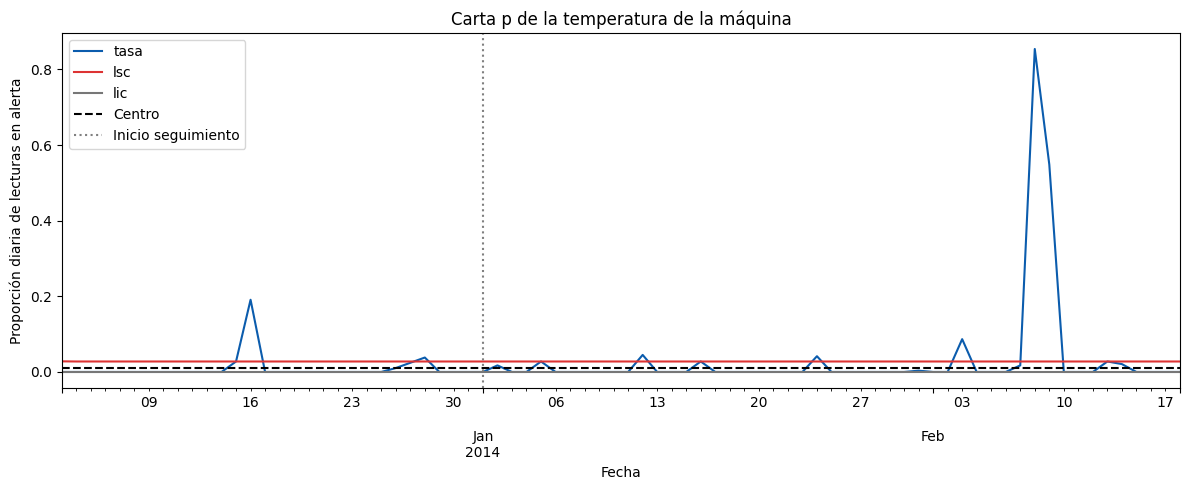

In [10]:
# ══════════════════════════════════════════════════════════════
# VISUALIZACIÓN DE LA CARTA P PARA EL MONITOREO DEL PROCESO
# ══════════════════════════════════════════════════════════════

# Grafica la proporción diaria de alertas y sus límites de control
ax = diario[["tasa", "lsc", "lic"]].plot(figsize=(12, 5), color=["#0B5CAD", "#D33", "#777"])  ### Representa la tasa diaria y los límites de control

# Añade la línea central correspondiente a la proporción promedio de alertas
ax.axhline(pbar, color="black", ls="--", label="Centro")  ### Señala la proporción promedio de la línea base

# Marca la fecha en que comienza el periodo de seguimiento
ax.axvline(CORTE, color="gray", ls=":", label="Inicio seguimiento")  ### Diferencia la línea base del periodo de monitoreo

# Configura los nombres de los ejes y el título de la carta de control
ax.set(ylabel="Proporción diaria de lecturas en alerta", xlabel="Fecha", title="Carta p de la temperatura de la máquina")  ### Define las etiquetas y el título del gráfico

# Muestra la leyenda, ajusta los espacios y presenta el gráfico
ax.legend(); plt.tight_layout(); plt.show()  ### Presenta la carta p con sus referencias estadísticas

### **Comportamiento de las alertas en la carta de control p**

La carta p muestra que la proporción diaria de alertas presenta variaciones durante todo el periodo analizado. Se observa un incremento importante en la línea base alrededor del 16 de diciembre, así como desviaciones puntuales durante enero y los primeros días de febrero. Sin embargo, el comportamiento más crítico ocurre el **8 y 9 de febrero de 2014**, cuando la proporción de alertas alcanza aproximadamente el 85.42 % y 54.86 %, respectivamente, superando ampliamente el límite superior de control (2.77 %). Estas señales evidencian un cambio significativo respecto al comportamiento habitual de la máquina y permiten identificar fechas que requieren una revisión operativa prioritaria.

| Elemento | Valor observado | Significado |
|---|---:|---|
| Línea central | 1.007 % | Proporción promedio de alertas de la línea base |
| Límite superior (LSC) | 2.7724 % | Umbral superior de control |
| Pico del 16/12/2013 | 19.10 % aprox. | Desviación durante la línea base |
| Pico del 08/02/2014 | 85.42 % | Mayor concentración de alertas |
| Pico del 09/02/2014 | 54.86 % | Persistencia del comportamiento anómalo |
| Días fuera de control en seguimiento | 8 | Señales que requieren análisis operativo |

## **Paso 6. Convertir alertas en una cola de revisión**
Un **episodio** agrupa las alertas separadas por 30 minutos o menos: es la unidad que el equipo revisa. La capacidad de **1 episodio por día** es un **supuesto académico**. La prioridad es la puntuación máxima del episodio. Se calcula la cola y se contrasta con las ventanas de NAB: un episodio coincide con una ventana si se superponen en el tiempo.

In [11]:
# ══════════════════════════════════════════════════════════════
# 6. PRIORIZACIÓN DE ALERTAS MEDIANTE UNA COLA DE REVISIÓN
# ══════════════════════════════════════════════════════════════

# Define la capacidad operativa asumida de revisión: un episodio por día
CAPACIDAD_DIA = 1  ### Establece el máximo de episodios que pueden revisarse diariamente

# Extrae las lecturas clasificadas como alertas junto con sus puntuaciones
alertas = feat.loc[feat.alerta, ["score"]].reset_index()  ### Conserva las puntuaciones de las lecturas anómalas

# Agrupa las alertas en episodios; inicia uno nuevo si transcurren más de 30 minutos
alertas["episodio"] = (alertas.timestamp.diff() > pd.Timedelta(minutes=30)).cumsum()  ### Identifica grupos de alertas temporalmente cercanas

# Resume cada episodio con su inicio, fin, cantidad de lecturas y puntuación máxima
episodios = alertas.groupby("episodio").agg(inicio=("timestamp", "min"), fin=("timestamp", "max"),
                                            lecturas=("score", "size"), score_max=("score", "max"))  ### Consolida las características de cada episodio

# Asigna a cada episodio la fecha correspondiente a su inicio
episodios["dia"] = episodios.inicio.dt.normalize()  ### Determina el día de registro del episodio

# Identifica si cada episodio se superpone temporalmente con alguna ventana de referencia NAB
episodios["en_ventana"] = [any((i <= b) and (f >= a) for a, b in ventanas) for i, f in zip(episodios.inicio, episodios.fin)]  ### Contrasta los episodios con las anomalías de referencia

# Conserva únicamente los episodios pertenecientes al periodo de seguimiento
ep = episodios[episodios.inicio >= CORTE].copy()  ### Filtra los eventos del periodo de monitoreo

# Ordena los episodios de cada día según su puntuación máxima, de mayor a menor
ep["orden_dia"] = ep.groupby("dia").score_max.rank(method="first", ascending=False)  ### Prioriza los episodios según su nivel máximo de rareza

# Marca como revisables los episodios que se encuentran dentro de la capacidad diaria
ep["revisable"] = ep.orden_dia <= CAPACIDAD_DIA  ### Selecciona los episodios que pueden atenderse

# Muestra el total de episodios, los que pueden revisarse y los que quedan en cola
print("Episodios en el seguimiento:", len(ep), "· revisables:", int(ep.revisable.sum()), "· en cola:", int((~ep.revisable).sum()))  ### Resume la carga operativa de revisión

# Cuenta los episodios que coinciden con las ventanas de anomalía de referencia
print("Episodios que coinciden con una ventana:", int(ep.en_ventana.sum()))  ### Cuantifica la coincidencia con las ventanas NAB

# Calcula cuántas lecturas alertadas del seguimiento coinciden con las ventanas de referencia NAB
print("Lecturas en alerta dentro de ventanas:", int((feat.loc[~base, "alerta"] & en_ventana[~base]).sum()), "de", int(feat.loc[~base, "alerta"].sum()))  ### Mide las alertas ubicadas dentro de los periodos de referencia

# Presenta los diez episodios con mayor puntuación máxima para facilitar su priorización
display(ep.sort_values("score_max", ascending=False).head(10).round(3))  ### Muestra los eventos de mayor prioridad operativa

Episodios en el seguimiento: 17 · revisables: 11 · en cola: 6
Episodios que coinciden con una ventana: 2
Lecturas en alerta dentro de ventanas: 404 de 495


,inicio,fin,lecturas,score_max,dia,en_ventana,orden_dia,revisable
episodio,,,,,,,,
18,2014-02-08 02:40:00,2014-02-09 13:05:00,403,0.793,2014-02-08,True,1.0,True
15,2014-02-03 11:50:00,2014-02-03 13:10:00,17,0.761,2014-02-03,False,1.0,True
12,2014-01-24 12:50:00,2014-01-24 13:45:00,12,0.679,2014-01-24,False,1.0,True
14,2014-02-03 00:10:00,2014-02-03 00:45:00,8,0.660,2014-02-03,False,2.0,False
9,2014-01-12 09:35:00,2014-01-12 10:10:00,8,0.644,2014-01-12,False,1.0,True
19,2014-02-13 19:30:00,2014-02-13 19:45:00,4,0.640,2014-02-13,False,1.0,True
8,2014-01-12 08:25:00,2014-01-12 08:45:00,5,0.640,2014-01-12,False,2.0,False
11,2014-01-16 13:00:00,2014-01-16 13:25:00,6,0.637,2014-01-16,False,1.0,True
7,2014-01-05 17:50:00,2014-01-05 18:25:00,8,0.634,2014-01-05,False,1.0,True


### **Priorización de episodios y capacidad de revisión operativa**

El proceso de agrupación identificó **17 episodios de anomalía** durante el seguimiento. Bajo el supuesto académico de una capacidad de revisión de un episodio por día, 11 episodios quedaron como revisables y 6 permanecieron en cola. De los 17 episodios, únicamente 2 coincidieron temporalmente con las ventanas de referencia de NAB. Asimismo, 404 de las 495 lecturas alertadas se ubicaron dentro de dichas ventanas, lo que representa aproximadamente el 81.62 %. Destaca el episodio del 8 al 9 de febrero, que concentró 403 lecturas y obtuvo la mayor puntuación de anomalía (0.793), por lo que constituye la principal prioridad operativa.

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Episodios detectados | 17 | Eventos agrupados para revisión |
| Episodios revisables | 11 | Episodios priorizados según la capacidad diaria |
| Episodios en cola | 6 | Eventos pendientes de revisión |
| Episodios coincidentes con ventanas NAB | 2 | Episodios con superposición temporal con anomalías de referencia |
| Lecturas alertadas dentro de ventanas | 404 de 495 (81.62 %) | Alertas ubicadas en periodos de referencia |
| Mayor puntuación de anomalía | 0.793 | Valor máximo registrado en el episodio principal |
| Episodio más crítico | 08/02/2014 al 09/02/2014 | Concentró 403 lecturas alertadas |

## **Paso 7. Sensibilidad del umbral**
Compare los percentiles base 98, 99 y 99,5. Para cada uno reporte alertas de seguimiento, episodios, episodios que coinciden con una ventana, días fuera de control y cola con la capacidad de 1 episodio por día. El umbral se calcula siempre en la línea base.

In [12]:
# ══════════════════════════════════════════════════════════════
# 7. ANÁLISIS DE SENSIBILIDAD DEL UMBRAL DE ANOMALÍAS
# ══════════════════════════════════════════════════════════════

# Inicializa una lista para almacenar los indicadores de cada percentil evaluado
filas = []  ### Almacena los resultados de cada escenario

# Evalúa tres umbrales: percentiles 98, 99 y 99.5 de la línea base
for q in [0.98, 0.99, 0.995]:

    # Calcula el umbral correspondiente al percentil evaluado usando solo la línea base
    corte_q = feat.loc[base, "score"].quantile(q)  ### Establece el umbral de detección

    # Clasifica las lecturas como alertas cuando su puntuación alcanza el umbral
    a = feat.score >= corte_q  ### Identifica las lecturas anómalas

    # Calcula la proporción de alertas de la línea base para establecer el control estadístico
    pq = a[base].mean()  ### Determina la proporción de referencia

    # Calcula el número de lecturas registradas por día
    n_dia = a.groupby(a.index.normalize()).size()  ### Obtiene el tamaño de muestra diario

    # Calcula el número de alertas registradas por día
    k_dia = a.groupby(a.index.normalize()).sum()  ### Cuantifica las alertas diarias

    # Calcula el límite superior de control diario para el percentil evaluado
    lsc_q = pq + 3 * np.sqrt(pq * (1 - pq) / n_dia)  ### Establece el límite superior de control

    # Cuenta los días del seguimiento cuya proporción de alertas supera el límite superior
    fuera_q = int(((k_dia / n_dia > lsc_q) & (n_dia.index >= CORTE)).sum())  ### Identifica los días fuera de control

    # Obtiene las fechas de las lecturas clasificadas como alertas
    ix = a[a].index.to_series()  ### Extrae las fechas de las anomalías

    # Agrupa las alertas en episodios cuando están separadas por más de 30 minutos
    nuevo = (ix.diff() > pd.Timedelta(minutes=30)).cumsum()  ### Delimita los episodios de anomalía

    # Construye una tabla con el inicio y fin de cada episodio detectado
    e = pd.DataFrame({"inicio": ix.groupby(nuevo).min(), "fin": ix.groupby(nuevo).max()})  ### Resume la duración de cada episodio

    # Conserva únicamente los episodios correspondientes al periodo de seguimiento
    e = e[e.inicio >= CORTE]  ### Filtra los episodios del periodo de monitoreo

    # Identifica los episodios que se superponen con las ventanas de referencia NAB
    e["en_ventana"] = [any((i <= b2) and (f >= a2) for a2, b2 in ventanas) for i, f in zip(e.inicio, e.fin)]  ### Contrasta con las ventanas de referencia

    # Calcula los episodios que exceden la capacidad diaria y quedan pendientes en la cola
    cola = int((e.groupby(e.inicio.dt.normalize()).size() - CAPACIDAD_DIA).clip(lower=0).sum())  ### Cuantifica los episodios pendientes

    # Registra los indicadores obtenidos para el percentil evaluado
    filas.append({"percentil_base": q, "umbral": corte_q, "alertas": int(a[~base].sum()), "episodios": len(e),
                  "en_ventana": int(e.en_ventana.sum()), "dias_fuera": fuera_q, "cola": cola})  ### Consolida las métricas del escenario

# Consolida los resultados de los tres escenarios en un DataFrame
sensibilidad = pd.DataFrame(filas)  ### Construye la tabla comparativa

# Presenta la comparación de los indicadores obtenidos
display(sensibilidad)  ### Muestra los resultados del análisis de sensibilidad

,percentil_base,umbral,alertas,episodios,en_ventana,dias_fuera,cola
0,0.980,0.559949,686,31,4,11,15
1,0.990,0.606017,495,17,2,8,6
2,0.995,0.692755,31,3,2,3,0


### **Comparación de sensibilidad de los umbrales de detección**

El análisis evidencia que el percentil seleccionado influye directamente en la cantidad de anomalías detectadas y en la carga operativa. Con el percentil 98 se identificaron 686 alertas y 31 episodios, generando una cola de 15 episodios pendientes. El percentil 99 ofrece un escenario intermedio, con 495 alertas, 17 episodios y 6 pendientes. En cambio, el percentil 99.5 reduce considerablemente las alertas a 31, identifica 3 episodios y elimina la cola operativa. Sin embargo, también disminuye la cantidad de días fuera de control y de episodios detectados. Por tanto, un umbral más estricto reduce la carga de revisión, pero puede dejar sin detectar eventos relevantes.

| Indicador | P98 | P99 | P99.5 |
|---|---:|---:|---:|
| Umbral | 0.559949 | 0.606017 | 0.692755 |
| Alertas de seguimiento | 686 | 495 | 31 |
| Episodios detectados | 31 | 17 | 3 |
| Episodios coincidentes con NAB | 4 | 2 | 2 |
| Días fuera de control | 11 | 8 | 3 |
| Episodios pendientes en cola | 15 | 6 | 0 |

| Escenario | Evaluación operativa |
|---|---|
| P98 | Mayor sensibilidad, pero genera una carga elevada de revisión |
| P99 | Equilibrio entre detección de anomalías y capacidad operativa |
| P99.5 | Menor carga de revisión, pero puede omitir eventos relevantes |

## **Tres retos individuales — diez ítems**
Responda cada pregunta con sus propias palabras y con las cifras de su ejecución.

### **Pregunta 1.1**
Cuantifique las marcas repetidas, los huecos y el rango de la serie, y explique dos causas posibles de las lecturas muy bajas.



### **Cuantificación de la calidad y rango de la serie temporal**

La serie original contiene **22,695 registros**, de los cuales se identificaron **12 marcas de tiempo repetidas**, conservando la primera lectura de cada instante. Después de eliminar duplicados, quedaron 22,683 registros útiles. No se detectaron huecos ni intervalos irregulares, ya que todas las lecturas consecutivas mantienen la frecuencia de 5 minutos. El rango de temperatura fue de **2.08 a 108.51**, con una amplitud de 106.43 unidades. Las 12 lecturas inferiores a 20 podrían explicarse por dos causas: una falla o interrupción del sensor que genere mediciones incorrectas, o una condición operativa anormal de la máquina que provoque una disminución real de la temperatura. Estas posibilidades deben verificarse antes de clasificar las lecturas como fallas físicas.

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Registros originales | 22,695 | Total de observaciones de la fuente |
| Marcas repetidas | 12 | Registros duplicados identificados |
| Registros útiles | 22,683 | Observaciones después de eliminar duplicados |
| Huecos o intervalos irregulares | 0 | No se detectaron desviaciones respecto a los 5 minutos |
| Temperatura mínima | 2.08 | Menor lectura registrada |
| Temperatura máxima | 108.51 | Mayor lectura registrada |
| Amplitud del rango | 106.43 | Diferencia entre temperatura máxima y mínima |
| Lecturas inferiores a 20 | 12 | Observaciones que requieren revisión |

### **Pregunta 1.2**
Describa dos episodios del top 10 con cifras (inicio, duración, lecturas en alerta y puntuación) y dos explicaciones operativas posibles para cada uno.



### **Análisis de episodios críticos y posibles causas operativas**

Del top 10 de episodios detectados, destaca el **episodio 18**, iniciado el 08/02/2014 a las 02:40 y finalizado el 09/02/2014 a las 13:05, con una duración de 34 horas y 25 minutos. Registró 403 lecturas en alerta y una puntuación máxima de 0.793, siendo el evento de mayor prioridad. Por otro lado, el **episodio 15**, ocurrido el 03/02/2014 entre las 11:50 y las 13:10, tuvo una duración de 1 hora y 20 minutos, con 17 lecturas en alerta y una puntuación máxima de 0.761.

| Episodio | Inicio | Duración | Lecturas en alerta | Puntuación máxima |
|---|---|---|---:|---:|
| 18 | 08/02/2014 02:40 | 34 h 25 min | 403 | 0.793 |
| 15 | 03/02/2014 11:50 | 1 h 20 min | 17 | 0.761 |

**Posibles explicaciones operativas:**

**Episodio 18:**
1. Sobrecalentamiento prolongado debido a una falla en el sistema de refrigeración o ventilación de la máquina.
2. Operación continua bajo una carga superior a la capacidad normal del equipo, generando un comportamiento térmico anormal.

**Episodio 15:**
1. Variación repentina de la carga de trabajo que provocó un incremento inusual de la temperatura.
2. Intermitencia en el sistema de refrigeración o una anomalía temporal del sensor de temperatura.

Estas explicaciones son hipótesis operativas que requieren contrastarse con registros de mantenimiento, carga de trabajo y funcionamiento del sistema de refrigeración.

### **Pregunta 1.3**
Identifique los días fuera de control e indique por qué son señales para investigar.



### **Identificación de días fuera de control estadístico**

Mediante la carta p se identificaron **8 días fuera de control durante el periodo de seguimiento**, en los cuales la proporción diaria de alertas superó el límite superior de control de **2.7724 %**. Las fechas detectadas fueron el 5, 12, 16 y 24 de enero, y el 3, 8, 9 y 13 de febrero de 2014. Destacan especialmente el 8 y 9 de febrero, con tasas de alertas de 85.42 % y 54.86 %, respectivamente. Estos días constituyen señales para investigar porque presentan una frecuencia de lecturas atípicas significativamente superior al comportamiento promedio de la línea base, lo que podría indicar cambios en las condiciones operativas, fallas de componentes o problemas de medición.

| Fecha | Alertas | Tasa de alertas | LSC | Motivo de investigación |
|---|---:|---:|---:|---|
| 05/01/2014 | 8 | 2.78 % | 2.77 % | Supera ligeramente el límite de control |
| 12/01/2014 | 13 | 4.51 % | 2.77 % | Incremento de lecturas atípicas |
| 16/01/2014 | 8 | 2.78 % | 2.77 % | Desviación del comportamiento esperado |
| 24/01/2014 | 12 | 4.17 % | 2.77 % | Mayor frecuencia de anomalías |
| 03/02/2014 | 25 | 8.68 % | 2.77 % | Incremento considerable de alertas |
| 08/02/2014 | 246 | 85.42 % | 2.77 % | Concentración crítica de anomalías |
| 09/02/2014 | 158 | 54.86 % | 2.77 % | Persistencia del comportamiento anómalo |
| 13/02/2014 | 8 | 2.78 % | 2.77 % | Nueva desviación del proceso |

### **Pregunta 1.4**
Proponga tres verificaciones externas antes de concluir una falla.



### **Verificaciones externas para confirmar posibles fallas operativas**

Antes de concluir que existe una falla en la máquina, se deben realizar tres verificaciones externas que permitan contrastar las anomalías detectadas por el modelo con las condiciones reales de operación:

1. **Inspección del sensor de temperatura:** verificar su calibración, conexiones eléctricas y estado físico para descartar lecturas incorrectas ocasionadas por errores de medición.

2. **Revisión del sistema de refrigeración:** comprobar el funcionamiento de ventiladores, filtros, circulación de aire y componentes de enfriamiento para identificar posibles problemas de disipación térmica.

3. **Consulta de registros operativos y de mantenimiento:** revisar la carga de trabajo, horas de funcionamiento, intervenciones técnicas y reportes de incidentes para determinar si las anomalías coinciden con cambios operativos o mantenimientos.

Estas verificaciones permiten validar las alertas del modelo con evidencia física y documental antes de confirmar una falla y ejecutar acciones correctivas.

### **Pregunta 2.1**
Compare los tres umbrales con alertas, episodios, días fuera de control y cola.



### **Comparación de umbrales y desempeño del modelo**

El análisis de sensibilidad muestra que el percentil utilizado modifica la capacidad de detección de anomalías y la carga operativa. El umbral P98 presenta la mayor sensibilidad, con 686 alertas, 31 episodios y 11 días fuera de control, pero genera una cola de 15 episodios pendientes. El P99 ofrece un equilibrio intermedio, con 495 alertas, 17 episodios, 8 días fuera de control y 6 episodios en cola. Finalmente, el P99.5 reduce considerablemente las alertas a 31, identifica 3 episodios y 3 días fuera de control, sin generar pendientes. Por tanto, un umbral más estricto disminuye la carga operativa, pero también reduce la detección de eventos potencialmente relevantes.

| Indicador | P98 | P99 | P99.5 |
|---|---:|---:|---:|
| Umbral | 0.559949 | 0.606017 | 0.692755 |
| Alertas | 686 | 495 | 31 |
| Episodios | 31 | 17 | 3 |
| Días fuera de control | 11 | 8 | 3 |
| Episodios en cola | 15 | 6 | 0 |

**Evaluación comparativa:**

- **P98:** Mayor detección de anomalías, pero genera una elevada carga de revisión.
- **P99:** Mantiene una capacidad de detección importante con una carga operativa moderada.
- **P99.5:** Reduce la carga de revisión, pero puede dejar sin identificar anomalías relevantes.

El percentil 99 representa una alternativa equilibrada entre sensibilidad de detección y capacidad operativa del equipo.

### **Pregunta 2.2**
Defienda un umbral bajo 1 revisión por día y declare el costo de oportunidad.



### **Selección del umbral y costo de oportunidad operativo**

Se propone utilizar el **percentil 99 (P99)**, con un umbral de **0.606017**, porque ofrece un equilibrio entre la detección de anomalías y la capacidad operativa de revisión. Este escenario identifica 495 alertas agrupadas en 17 episodios, de los cuales 11 son revisables y 6 quedan pendientes, considerando una capacidad de un episodio por día. Aunque el P99.5 elimina la cola de revisión, reduce los episodios detectados a solo 3, lo que podría ocasionar que eventos relevantes no sean investigados oportunamente.

**Costo de oportunidad:** Al seleccionar P99 en lugar de P98, se reducen 191 alertas, 14 episodios y 9 episodios pendientes, pero también se dejan de identificar algunos eventos que podrían representar anomalías operativas. Asimismo, los 6 episodios que exceden la capacidad de revisión representan el riesgo de retrasar la identificación de posibles fallas. Por ello, la organización debe equilibrar la carga de trabajo con el riesgo de no detectar eventos importantes.

### **Pregunta 2.3**
Para cada ventana de referencia del seguimiento, calcule cuántas horas antes o después de su inicio apareció el primer episodio y explique por qué esa diferencia no demuestra capacidad de predicción.



Para cada ventana de referencia del seguimiento, calcule cuántas horas antes o después de su inicio apareció el primer episodio y explique por qué esa diferencia no demuestra capacidad de predicción.

In [13]:
# ══════════════════════════════════════════════════════════════
# 8. ANÁLISIS TEMPORAL DE EPISODIOS FRENTE A VENTANAS NAB
# ══════════════════════════════════════════════════════════════

# Selecciona las ventanas de referencia correspondientes al seguimiento
ventanas_seg = [(a, b) for a, b in ventanas if a >= CORTE]  ### Filtra los periodos de referencia posteriores al inicio del seguimiento

# Inicializa una lista para almacenar las diferencias temporales
comparacion = []  ### Almacena los resultados de anticipación

# Recorre cada ventana de anomalía de referencia
for a, b in ventanas_seg:

    # Busca los episodios que comenzaron antes del inicio de la ventana
    anteriores = ep.loc[ep.inicio < a].copy()  ### Identifica episodios previos al evento de referencia

    # Selecciona el episodio anterior más cercano
    if not anteriores.empty:
        primero = anteriores.loc[anteriores.inicio.idxmax()]  ### Obtiene el episodio previo más reciente

        # Calcula las horas transcurridas entre el episodio y la ventana
        horas = (a - primero.inicio).total_seconds() / 3600  ### Cuantifica la anticipación temporal

        # Registra los datos de la comparación
        comparacion.append({"inicio_ventana": a, "episodio_previo": primero.inicio,
                            "horas_antes": round(horas, 2)})  ### Consolida la diferencia temporal

# Construye y presenta la tabla comparativa
comparacion = pd.DataFrame(comparacion)  ### Organiza los resultados
display(comparacion)

,inicio_ventana,episodio_previo,horas_antes
0,2014-01-27 14:20:00,2014-01-24 12:50:00,73.50
1,2014-02-07 14:55:00,2014-02-07 07:50:00,7.08


### **Evaluación de la anticipación de anomalías respecto a las ventanas de referencia**

La comparación temporal identificó dos episodios previos al inicio de las ventanas de referencia del periodo de seguimiento. Para la primera ventana, iniciada el 27/01/2014 a las 14:20, se detectó un episodio el 24/01/2014 a las 12:50, con una anticipación de **73.50 horas**. Para la segunda ventana, iniciada el 07/02/2014 a las 14:55, se identificó un episodio el mismo día a las 07:50, con una anticipación de **7.08 horas**. Estas diferencias indican que el modelo detectó comportamientos atípicos antes de ambos eventos de referencia; sin embargo, no demuestran capacidad predictiva, porque Isolation Forest identifica anomalías en lecturas ya observadas y no pronostica la ocurrencia futura de fallas. Además, no se ha demostrado que los episodios previos sean señales precursoras de los eventos posteriores.

| Ventana de referencia | Inicio de ventana | Episodio previo | Anticipación |
|---|---|---|---:|
| 1 | 27/01/2014 14:20 | 24/01/2014 12:50 | 73.50 horas |
| 2 | 07/02/2014 14:55 | 07/02/2014 07:50 | 7.08 horas |

**Limitación predictiva:** Para demostrar capacidad de predicción sería necesario definir un horizonte temporal, identificar señales precursoras y evaluar si las alertas anticipan fallas futuras en datos independientes, midiendo la precisión y las falsas alarmas.

### **Pregunta 3.1**
Repita la carta p con una línea base ampliada del 3 de diciembre al 15 de enero, reentrenando el modelo, e informe cambios.



Para esta prueba de robustez, se ampliará la línea base hasta el 15 de enero de 2014, se reentrenará Isolation Forest con ese periodo y se recalcularán las puntuaciones, el umbral P99 y la carta p. Después se compararán los días fuera de control con los obtenidos en el escenario original.

Es importante mantener el periodo de seguimiento posterior al 15 de enero para evaluar cómo cambia la detección al incorporar más datos históricos.

Nuevo umbral P99: 0.599724
Nueva proporción base: 0.01003
Alertas en la nueva línea base: 127
Alertas en el nuevo seguimiento: 501
Días fuera de control en el nuevo seguimiento: 6
Días fuera de control originales en el mismo periodo: 6
Fechas fuera de control: ['2014-01-16', '2014-01-24', '2014-02-03', '2014-02-08', '2014-02-09', '2014-02-13']


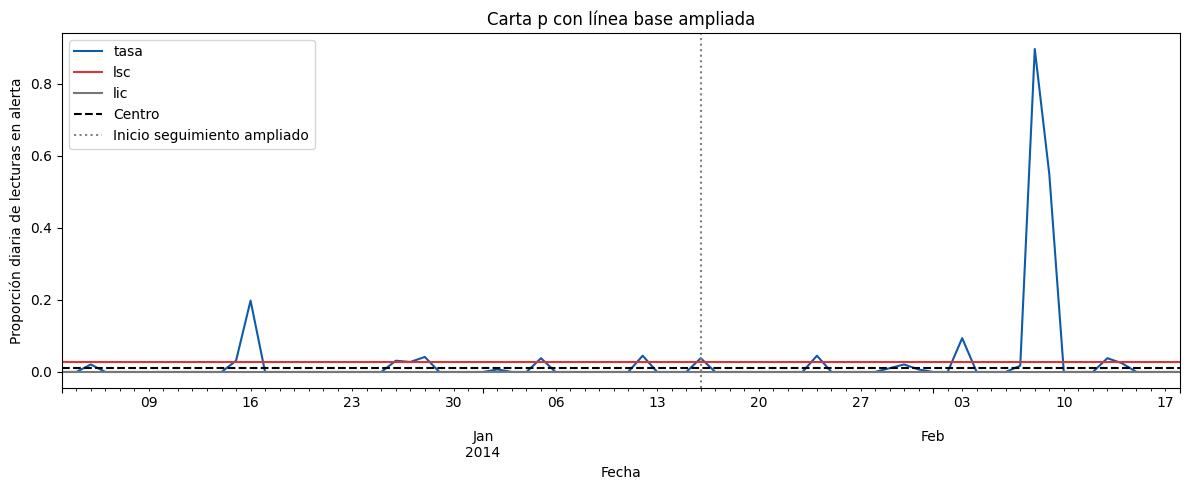

In [14]:
# ══════════════════════════════════════════════════════════════
# 9. PRUEBA DE ROBUSTEZ CON LÍNEA BASE AMPLIADA
# ══════════════════════════════════════════════════════════════

# Conserva las puntuaciones y alertas del modelo original
feat["score_original"] = feat["score"]  ### Guarda las puntuaciones del escenario inicial
feat["alerta_original"] = feat["alerta"]  ### Conserva las alertas originales
diario_original = diario.copy()  ### Almacena la carta p original
pbar_original = pbar  ### Conserva la proporción promedio original

# Define el nuevo periodo de referencia hasta el 15 de enero de 2014
CORTE_AMPLIADO = pd.Timestamp("2014-01-16")  ### Establece el inicio del nuevo seguimiento

# Identifica las observaciones correspondientes a la línea base ampliada
base_ampliada = feat.index < CORTE_AMPLIADO  ### Incluye los registros del 03/12/2013 al 15/01/2014

# Configura nuevamente el modelo Isolation Forest
modelo_ampliado = IsolationForest(n_estimators=150, max_samples=5000, random_state=2026, n_jobs=-1)  ### Mantiene los parámetros del modelo original

# Entrena el modelo utilizando exclusivamente la nueva línea base
modelo_ampliado.fit(feat.loc[base_ampliada, ["valor", "media_1h", "desv_1h", "cambio_1h"]])  ### Reentrena con más información histórica

# Calcula las nuevas puntuaciones de rareza para toda la serie
feat["score_ampliado"] = -modelo_ampliado.score_samples(feat[["valor", "media_1h", "desv_1h", "cambio_1h"]])  ### Actualiza la detección de anomalías

# Establece el nuevo umbral utilizando el percentil 99 de la línea base ampliada
umbral_ampliado = feat.loc[base_ampliada, "score_ampliado"].quantile(0.99)  ### Calcula el nuevo límite de rareza

# Clasifica las lecturas según el nuevo umbral
feat["alerta_ampliada"] = feat["score_ampliado"] >= umbral_ampliado  ### Genera las nuevas alertas

# Agrupa las nuevas alertas por día
diario_ampliado = feat.groupby(feat.index.normalize()).agg(
    lecturas=("alerta_ampliada", "size"),
    alertas=("alerta_ampliada", "sum")
)  ### Consolida las observaciones diarias

# Calcula la proporción promedio de alertas de la línea base ampliada
pbar_ampliado = feat.loc[base_ampliada, "alerta_ampliada"].mean()  ### Establece la nueva línea central

# Calcula la proporción diaria de alertas
diario_ampliado["tasa"] = diario_ampliado.alertas / diario_ampliado.lecturas  ### Obtiene la frecuencia diaria de anomalías

# Calcula los límites superior e inferior de control
diario_ampliado["lsc"] = pbar_ampliado + 3 * np.sqrt(pbar_ampliado * (1 - pbar_ampliado) / diario_ampliado.lecturas)  ### Calcula el límite superior
diario_ampliado["lic"] = np.maximum(0, pbar_ampliado - 3 * np.sqrt(pbar_ampliado * (1 - pbar_ampliado) / diario_ampliado.lecturas))  ### Calcula el límite inferior

# Identifica los días que presentan señales fuera de control
diario_ampliado["fuera"] = (diario_ampliado.tasa > diario_ampliado.lsc) | (diario_ampliado.tasa < diario_ampliado.lic)  ### Detecta desviaciones estadísticas

# Filtra los días correspondientes al nuevo periodo de seguimiento
seguimiento_ampliado = diario_ampliado.loc[CORTE_AMPLIADO:].copy()  ### Excluye los días incorporados a la línea base

# Calcula los días fuera de control del escenario original en el mismo periodo comparable
fuera_original_comparable = diario_original.loc[CORTE_AMPLIADO:, "fuera"].sum()  ### Recupera las señales originales desde el 16 de enero

# Presenta los indicadores del modelo reentrenado
print("Nuevo umbral P99:", round(umbral_ampliado, 6))  ### Muestra el nuevo umbral
print("Nueva proporción base:", round(pbar_ampliado, 5))  ### Muestra la nueva proporción promedio
print("Alertas en la nueva línea base:", int(feat.loc[base_ampliada, "alerta_ampliada"].sum()))  ### Cuantifica las alertas de referencia
print("Alertas en el nuevo seguimiento:", int(feat.loc[~base_ampliada, "alerta_ampliada"].sum()))  ### Cuantifica las alertas posteriores
print("Días fuera de control en el nuevo seguimiento:", int(seguimiento_ampliado.fuera.sum()))  ### Cuenta las señales del nuevo escenario
print("Días fuera de control originales en el mismo periodo:", int(fuera_original_comparable))  ### Permite una comparación temporal equivalente

# Presenta las fechas identificadas fuera de control
print("Fechas fuera de control:", [str(d)[:10] for d in seguimiento_ampliado.index[seguimiento_ampliado.fuera]])  ### Identifica los días críticos

# Grafica la nueva carta p
ax = diario_ampliado[["tasa", "lsc", "lic"]].plot(figsize=(12, 5), color=["#0B5CAD", "#D33", "#777"])  ### Visualiza la nueva proporción diaria y sus límites
ax.axhline(pbar_ampliado, color="black", ls="--", label="Centro")  ### Añade la nueva línea central
ax.axvline(CORTE_AMPLIADO, color="gray", ls=":", label="Inicio seguimiento ampliado")  ### Marca el inicio del nuevo seguimiento
ax.set(ylabel="Proporción diaria de lecturas en alerta", xlabel="Fecha", title="Carta p con línea base ampliada")  ### Configura el gráfico
ax.legend(); plt.tight_layout(); plt.show()  ### Presenta la carta p actualizada

### **Evaluación de robustez con una línea base ampliada**

Al ampliar la línea base hasta el 15 de enero de 2014 y reentrenar Isolation Forest, el nuevo umbral P99 disminuyó de **0.606017 a 0.599724**. La proporción promedio de alertas se mantuvo prácticamente estable, pasando de 1.007 % a 1.003 %. Las alertas del seguimiento aumentaron de 495 a 501; sin embargo, los días fuera de control permanecieron en 6, considerando el mismo periodo comparable desde el 16 de enero. Las fechas identificadas también se mantuvieron: 16 y 24 de enero, 3, 8, 9 y 13 de febrero. Esto evidencia que la ampliación de la línea base modificó ligeramente el umbral y la cantidad de alertas, pero conservó las principales señales de comportamiento anómalo.

| Indicador | Escenario original | Línea base ampliada |
|---|---:|---:|
| Umbral P99 | 0.606017 | 0.599724 |
| Proporción promedio de alertas | 1.007 % | 1.003 % |
| Alertas en el seguimiento | 495 | 501 |
| Días fuera de control | 6 | 6 |
| Fechas fuera de control | 6 | 6 |
| Inicio del seguimiento | 01/01/2014 | 16/01/2014 |

**Evaluación de estabilidad:** La carta p ampliada conserva los principales picos de anomalías, especialmente los registrados el 8 y 9 de febrero. Por tanto, el modelo presenta estabilidad relativa frente a la ampliación de la línea base, aunque se observan pequeñas variaciones en las puntuaciones y alertas detectadas.

### **Pregunta 3.2**
Compare el modelo con las cuatro variables y un modelo que usa solo la lectura (valor): alertas, episodios y coincidencia con las ventanas.



Para esta comparación se mantendrán los mismos parámetros de Isolation Forest y el percentil 99 como umbral. La única diferencia será la cantidad de variables utilizadas:
- Modelo multivariable: valor, media_1h, desv_1h y cambio_1h.
- Modelo univariable: únicamente valor.
Ambos modelos se entrenarán con la misma línea base original (hasta el 31 de diciembre de 2013) y se evaluarán sobre el mismo periodo de seguimiento.

In [16]:
# ══════════════════════════════════════════════════════════════
# 10. COMPARACIÓN DEL MODELO MULTIVARIABLE Y UNIVARIABLE
# ══════════════════════════════════════════════════════════════

# Define las variables utilizadas por cada modelo
variables_4 = ["valor", "media_1h", "desv_1h", "cambio_1h"]  ### Configura las cuatro variables derivadas
variables_1 = ["valor"]  ### Configura únicamente la lectura original

# Inicializa los modelos Isolation Forest con los mismos parámetros
modelo_4 = IsolationForest(n_estimators=150, max_samples=5000, random_state=2026, n_jobs=-1)  ### Modelo multivariable
modelo_1 = IsolationForest(n_estimators=150, max_samples=5000, random_state=2026, n_jobs=-1)  ### Modelo univariable

# Entrena ambos modelos utilizando exclusivamente la línea base
modelo_4.fit(feat.loc[base, variables_4])  ### Aprende patrones de las cuatro variables
modelo_1.fit(feat.loc[base, variables_1])  ### Aprende patrones únicamente del valor

# Calcula las puntuaciones de rareza para toda la serie y las convierte a Series de Pandas
score_4 = pd.Series(-modelo_4.score_samples(feat[variables_4]), index=feat.index)  ### Calcula la rareza multivariable
score_1 = pd.Series(-modelo_1.score_samples(feat[variables_1]), index=feat.index)  ### Calcula la rareza univariable

# Calcula los umbrales P99 utilizando las puntuaciones de la línea base
umbral_4 = score_4.loc[base].quantile(0.99)  ### Establece el umbral multivariable
umbral_1 = score_1.loc[base].quantile(0.99)  ### Establece el umbral univariable

# Clasifica las lecturas como alertas según cada umbral
alerta_4 = score_4 >= umbral_4  ### Genera alertas con cuatro variables
alerta_1 = score_1 >= umbral_1  ### Genera alertas con una variable

# Inicializa una lista para almacenar los resultados comparativos
resultados = []  ### Consolida los indicadores de ambos modelos

# Evalúa cada modelo con sus respectivas alertas y puntuaciones
for nombre, alerta in [("Multivariable (4 variables)", alerta_4),
                       ("Univariable (valor)", alerta_1)]:

    # Obtiene las fechas de las lecturas clasificadas como alertas
    ix = alerta[alerta].index.to_series()  ### Extrae las fechas de anomalías

    # Agrupa las alertas separadas por más de 30 minutos en episodios
    nuevo = (ix.diff() > pd.Timedelta(minutes=30)).cumsum()  ### Identifica episodios independientes

    # Construye una tabla con el inicio y fin de cada episodio
    e = pd.DataFrame({"inicio": ix.groupby(nuevo).min(), "fin": ix.groupby(nuevo).max()})  ### Resume los episodios

    # Conserva únicamente los episodios del periodo de seguimiento
    e = e[e.inicio >= CORTE].copy()  ### Filtra los eventos posteriores a la línea base

    # Identifica los episodios que coinciden con las ventanas de referencia NAB
    e["en_ventana"] = [any((i <= b) and (f >= a) for a, b in ventanas) for i, f in zip(e.inicio, e.fin)]  ### Evalúa la coincidencia temporal

    # Registra las métricas obtenidas para cada modelo
    resultados.append({
        "modelo": nombre,
        "umbral_P99": round(umbral_4 if nombre.startswith("Multi") else umbral_1, 6),
        "alertas": int(alerta[~base].sum()),
        "episodios": len(e),
        "coincidencias_NAB": int(e.en_ventana.sum())
    })  ### Consolida los indicadores de evaluación

# Construye la tabla comparativa de los dos modelos
comparacion_modelos = pd.DataFrame(resultados)  ### Organiza los resultados

# Presenta la comparación final
display(comparacion_modelos)  ### Muestra las métricas de ambos modelos

,modelo,umbral_P99,alertas,episodios,coincidencias_NAB
0,Multivariable (4 variables),0.606017,495,17,2
1,Univariable (valor),0.589176,459,4,1


### **Comparación del desempeño de modelos univariables y multivariables**

El modelo multivariable, que utiliza cuatro variables (`valor`, `media_1h`, `desv_1h` y `cambio_1h`), identificó 495 alertas agrupadas en 17 episodios, de los cuales 2 coincidieron con las ventanas de referencia NAB. Por otro lado, el modelo univariable, basado únicamente en la temperatura, detectó 459 alertas agrupadas en 4 episodios, con una coincidencia con NAB. Estos resultados muestran que incorporar variables derivadas permite identificar una mayor cantidad de episodios y obtener más coincidencias con los eventos de referencia, proporcionando una caracterización más completa del comportamiento anómalo.

| Indicador | Multivariable (4 variables) | Univariable (valor) |
|---|---:|---:|
| Umbral P99 | 0.606017 | 0.589176 |
| Alertas | 495 | 459 |
| Episodios | 17 | 4 |
| Coincidencias con ventanas NAB | 2 | 1 |

**Evaluación:** El modelo multivariable presenta mayor capacidad para identificar episodios de comportamiento atípico y una mayor coincidencia con las ventanas de referencia. Por ello, resulta más informativo para el monitoreo de la máquina. Sin embargo, estos resultados no demuestran por sí solos una mayor precisión predictiva, ya que sería necesario evaluar también falsos positivos y falsos negativos.

### **Pregunta 3.3**
Redacte una recomendación ejecutiva de ocho líneas con cifras, responsable, acción, límite y condición de revisión.



### **Recomendación ejecutiva para el monitoreo de anomalías**

1. **Responsable:** El jefe de mantenimiento deberá supervisar el monitoreo térmico de la máquina mediante el modelo Isolation Forest.
2. **Modelo seleccionado:** Implementar el modelo multivariable de cuatro características, que identificó 495 alertas y 17 episodios.
3. **Umbral:** Establecer el percentil 99 (P99), equivalente a una puntuación de rareza de 0.606017.
4. **Prioridad:** Investigar primero los episodios con mayor puntuación, especialmente el registrado entre el 8 y 9 de febrero, con 403 lecturas en alerta.
5. **Acción:** Verificar sensores, sistema de refrigeración y registros operativos antes de confirmar una falla.
6. **Límite operativo:** Mantener como supuesto inicial una capacidad de revisión de un episodio por día, priorizando los eventos de mayor puntuación.
7. **Condición de revisión:** Recalibrar el umbral si aumentan las alertas, se acumulan episodios pendientes o aparecen nuevas señales fuera de control.
8. **Resultado esperado:** Reducir el riesgo de fallas no detectadas mediante el seguimiento diario, la validación técnica y la actualización periódica del modelo.

## Entrega
Suba el notebook ejecutado a su GitHub personal en `semana12/` y comparta también el enlace a su Colab. Incluya las diez respuestas individuales y un cierre que distinga alerta estadística, investigación y falla demostrada. El cuestionario individual de la semana se rinde aparte.